# **CP462 Project:  HealthSense**

# หัวข้อ : **HealthSense: Predicting Chronic Disease Risk from Daily Lifestyle**

**สมาชิก:**
<br>1) นายวัชรพงศ์ มาลัง (ID: 67102010174)
<br>2) นาย นราธิป สุวณิชย์ (ID: 67102010517)
<br><br>
**Dataset:** Diabetes Prediction Dataset (100,000 rows, 9 columns) <br>
**Source:** Kaggle — https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset

## Problem Statement

**ที่มาและความสำคัญ**

โรคเรื้อรัง (เบาหวาน, ความดันสูง, โรคหัวใจ) เป็นสาเหตุการตายอันดับต้น ๆ และส่วนใหญ่ป้องกันได้จากพฤติกรรมการใช้ชีวิต (lifestyle) เช่น การออกกำลังกาย การนอน การสูบบุหรี่ อาหารการกิน

**ปัญหาที่ต้องการแก้ไขด้วยข้อมูล**

จะทำนายความเสี่ยงของการเป็นโรคเรื้อรัง (chronic disease) จากข้อมูลพฤติกรรมประจำวันได้อย่างไร เพื่อให้คนรู้ตัวก่อนที่จะป่วยจริง

**ประโยชน์กับใคร**

ประชาชนทั่วไปที่อยากประเมินความเสี่ยงตัวเอง, หน่วยงานสาธารณสุขที่อยากคัดกรองกลุ่มเสี่ยง, บริษัทประกันสุขภาพ

## **Import Packages**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import kagglehub

sns.set_style("whitegrid")

# ตั้งฟอนต์ไทยหลังสุด เพื่อไม่ให้ seaborn เขียนทับ
# ติดตั้งฟอนต์ไทย (ต้องรันก่อนใช้ครั้งแรกในแต่ละ session)
!apt-get -qq install -y fonts-thai-tlwg > /dev/null

thai_font_path = "/usr/share/fonts/truetype/tlwg/Loma.ttf"
fm.fontManager.addfont(thai_font_path)
thai_font_name = fm.FontProperties(fname=thai_font_path).get_name()
plt.rcParams["font.family"] = thai_font_name
plt.rcParams["axes.unicode_minus"] = False


print("ฟอนต์ที่ใช้อยู่:", plt.rcParams["font.family"])

ฟอนต์ที่ใช้อยู่: ['Loma']


In [ ]:
# ติดตั้งไลบรารีที่จำเป็น (รันครั้งเดียวใน Colab)
!pip install kagglehub -q

## **Import Dataset**

### Dataset Description

**คำอธิบายชุดข้อมูล (Dataset Description)**

- **Dataset เกี่ยวกับอะไร**: เป็นชุดข้อมูลทางการแพทย์และประชากรศาสตร์ของผู้ป่วย ที่รวบรวมไว้เพื่อใช้ทำนายว่าบุคคลนั้นเป็นโรคเบาหวานหรือไม่ โดยมีทั้งข้อมูลพื้นฐาน (เพศ, อายุ), ประวัติสุขภาพ (ความดันสูง, โรคหัวใจ), พฤติกรรม (ประวัติการสูบบุหรี่) และค่าตรวจทางคลินิก (BMI, HbA1c, ระดับน้ำตาลในเลือด)
- **แหล่งที่มา (Source)**: Kaggle — https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset
- **จุดประสงค์ของการใช้**: เพื่อวิเคราะห์ความสัมพันธ์ระหว่างปัจจัยด้านพฤติกรรม/สุขภาพกับการเป็นโรคเบาหวาน และนำไปสร้างแบบจำลองทำนายความเสี่ยงเป็นเบาหวาน (chronic disease risk prediction)

**ขนาดของข้อมูล (Size of Dataset)**
- จำนวนแถว: 100,000 rows (1 แถว = ข้อมูลผู้ป่วย 1 คน)
- จำนวนคอลัมน์: 9 columns (8 features + 1 target)

**รายละเอียดของแต่ละคอลัมน์ (Attributes/Features)**

| คอลัมน์ | ความหมาย | ชนิดข้อมูล |
|---|---|---|
| gender | เพศ (Male / Female / Other) | Categorical |
| age | อายุ (0–80 ปี) | Numeric |
| hypertension | เป็นความดันโลหิตสูงหรือไม่ (0/1) | Binary |
| heart_disease | เป็นโรคหัวใจหรือไม่ (0/1) | Binary |
| smoking_history | ประวัติการสูบบุหรี่ (never, former, current, not current, ever, No Info) | Categorical (Lifestyle) |
| bmi | ดัชนีมวลกาย (Body Mass Index) | Numeric |
| HbA1c_level | ระดับน้ำตาลสะสมเฉลี่ยใน 2-3 เดือนที่ผ่านมา | Numeric |
| blood_glucose_level | ระดับน้ำตาลในเลือด ณ ขณะตรวจ | Numeric |
| diabetes | **Target** — เป็นเบาหวาน (1) หรือไม่ (0) | Binary |

**การนำเข้าข้อมูล (Data Import)**: ดาวน์โหลดไฟล์ CSV จาก Kaggle ผ่านไลบรารี `kagglehub` แล้วโหลดเข้า pandas DataFrame ด้วย `pd.read_csv()` ใน Google Colab

เนื่องจาก dataset นี้เป็น public dataset จึง**ไม่ต้องอัปโหลดไฟล์ `kaggle.json`** — `kagglehub` ดาวน์โหลดได้เลยโดยไม่ต้อง login
(ถ้าอยากใช้บัญชี Kaggle ของตัวเอง ให้เพิ่ม `KAGGLE_USERNAME` และ `KAGGLE_KEY` ในแท็บ Secrets 🔑 ด้านซ้ายของ Colab แล้วเปิด Notebook access โค้ดจะดึงไปใช้ให้อัตโนมัติ)

In [ ]:
import os

# ไม่ต้องอัปโหลด kaggle.json แล้ว
# dataset นี้เป็น public dataset จึงให้ kagglehub ดาวน์โหลดได้เลยโดยไม่ต้อง login
# (ถ้าตั้งค่า KAGGLE_USERNAME / KAGGLE_KEY ไว้ใน Colab Secrets 🔑 จะดึงมาใช้ให้อัตโนมัติ)
try:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("ใช้ Kaggle credentials จาก Colab Secrets")
except Exception:
    print("ไม่ได้ตั้งค่า Colab Secrets → ดาวน์โหลดแบบไม่ login (public dataset)")

ไม่ได้ตั้งค่า Colab Secrets → ดาวน์โหลดแบบไม่ login (public dataset)


In [ ]:
# ดาวน์โหลด dataset จาก Kaggle
dataset_path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("ไฟล์ที่ดาวน์โหลดมา:", os.listdir(dataset_path))

csv_file = os.path.join(dataset_path, "diabetes_prediction_dataset.csv")
df = pd.read_csv(csv_file)

print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
ไฟล์ที่ดาวน์โหลดมา: ['diabetes_prediction_dataset.csv']
Shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
# ข้อมูลทั่วไปของ dataset: จำนวนแถว/คอลัมน์, ชนิดข้อมูล
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [ ]:
# สถิติเชิงพรรณนาเบื้องต้นของคอลัมน์ตัวเลข
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00


### Data Cleansing

In [ ]:
# 1. ตรวจสอบ missing values แบบ NaN ทั่วไป
print("Missing values (NaN) ต่อคอลัมน์:")
print(df.isnull().sum())

Missing values (NaN) ต่อคอลัมน์:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [ ]:
# 2. ตรวจ missing value ที่ซ่อนอยู่ใน smoking_history (ค่า 'No Info')
print(df["smoking_history"].value_counts())
no_info_ratio = (df["smoking_history"] == "No Info").mean()
print(f"\nสัดส่วนที่เป็น 'No Info': {no_info_ratio:.2%}")

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

สัดส่วนที่เป็น 'No Info': 35.82%


In [ ]:
# สัดส่วน 'No Info' ค่อนข้างมาก การลบทิ้งจะเสียข้อมูลไปเยอะเกินไป
# จึงเลือกเก็บไว้เป็นอีกหนึ่ง category ชื่อ 'unknown' แทน เพื่อไม่ให้เสียข้อมูลแถวอื่น ๆ ไปด้วย
df["smoking_history"] = df["smoking_history"].replace("No Info", "unknown")
df["smoking_history"].value_counts()

,count
smoking_history,
unknown,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [ ]:
# 3. ตรวจสอบและลบแถวที่ซ้ำกัน (duplicate rows)
n_dup = df.duplicated().sum()
print(f"จำนวนแถวที่ซ้ำกัน: {n_dup}")

df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"จำนวนแถวก่อนลบ: {len(df)}, หลังลบ duplicate: {len(df_clean)}")

จำนวนแถวที่ซ้ำกัน: 3854
จำนวนแถวก่อนลบ: 100000, หลังลบ duplicate: 96146


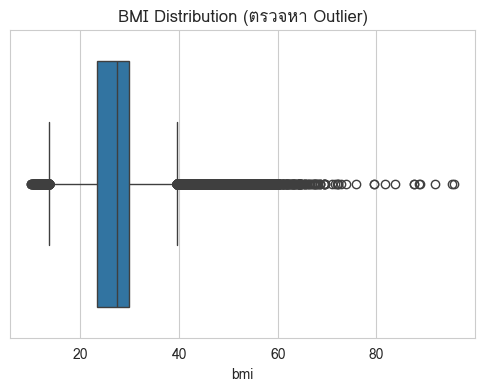

count    96146.000000
mean        27.321461
std          6.767716
min         10.010000
25%         23.400000
50%         27.320000
75%         29.860000
max         95.690000
Name: bmi, dtype: float64


In [ ]:
# 4. ตรวจ outlier ของ bmi ด้วย boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(x=df_clean["bmi"])
plt.title("BMI Distribution (ตรวจหา Outlier)")
plt.show()

print(df_clean["bmi"].describe())

In [ ]:
# 5. แปลงคอลัมน์ binary/categorical ให้เป็น dtype ที่เหมาะสม
df_clean["hypertension"] = df_clean["hypertension"].astype("category")
df_clean["heart_disease"] = df_clean["heart_disease"].astype("category")
df_clean["diabetes"] = df_clean["diabetes"].astype("category")
df_clean["gender"] = df_clean["gender"].astype("category")
df_clean["smoking_history"] = df_clean["smoking_history"].astype("category")

df_clean.dtypes

,0
gender,category
age,float64
hypertension,category
heart_disease,category
smoking_history,category
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,category


## **Explore Data Analysis**

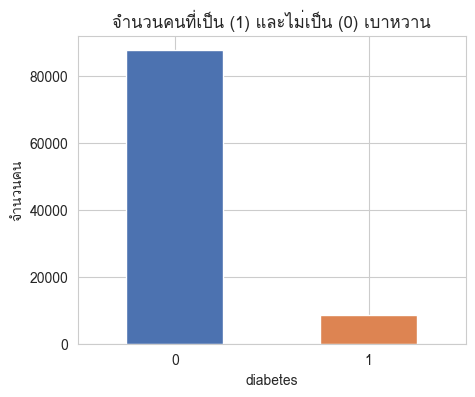

In [ ]:
# กราฟ 1: สัดส่วนคนที่เป็น/ไม่เป็นเบาหวาน (Bar chart)
plt.figure(figsize=(5, 4))
df_clean["diabetes"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("จำนวนคนที่เป็น (1) และไม่เป็น (0) เบาหวาน")
plt.xlabel("diabetes")
plt.ylabel("จำนวนคน")
plt.xticks(rotation=0)
plt.show()

**คำอธิบาย:** ข้อมูลมีลักษณะ imbalanced คือกลุ่มไม่เป็นเบาหวานมีจำนวนมากกว่ากลุ่มเป็นเบาหวานอย่างชัดเจน เป็นประเด็นที่ต้องพิจารณาต่อในการสร้างโมเดล Part 2

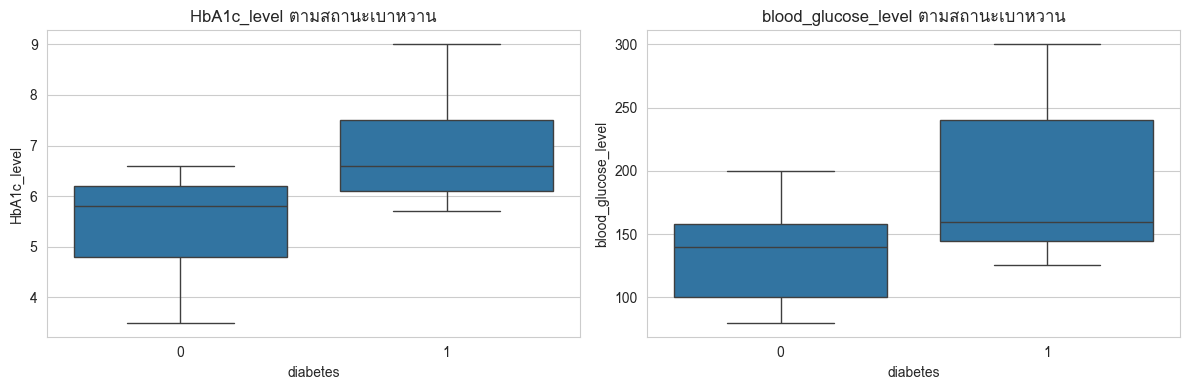

In [ ]:
# กราฟ 2: HbA1c_level และ blood_glucose_level เทียบระหว่างกลุ่มเป็น/ไม่เป็นเบาหวาน (Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="diabetes", y="HbA1c_level", data=df_clean, ax=axes[0])
axes[0].set_title("HbA1c_level ตามสถานะเบาหวาน")

sns.boxplot(x="diabetes", y="blood_glucose_level", data=df_clean, ax=axes[1])
axes[1].set_title("blood_glucose_level ตามสถานะเบาหวาน")
plt.tight_layout()
plt.show()

**คำอธิบาย:** กลุ่มที่เป็นเบาหวานมีค่าทั้งสองตัวสูงกว่ากลุ่มที่ไม่เป็นอย่างชัดเจน สอดคล้องกับหลักการแพทย์ที่ใช้ค่าเหล่านี้วินิจฉัยเบาหวานโดยตรง

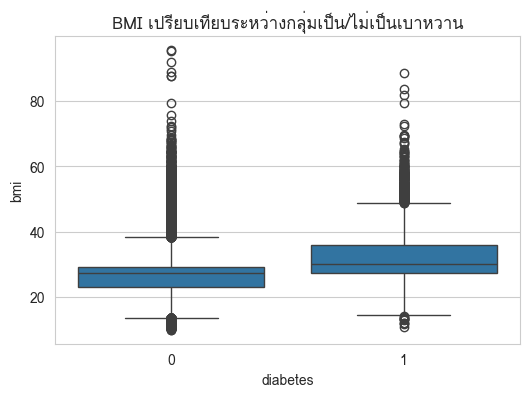

In [ ]:
# กราฟ 3: BMI เทียบระหว่างกลุ่มเป็น/ไม่เป็นเบาหวาน (Boxplot)
plt.figure(figsize=(6, 4))
sns.boxplot(x="diabetes", y="bmi", data=df_clean)
plt.title("BMI เปรียบเทียบระหว่างกลุ่มเป็น/ไม่เป็นเบาหวาน")
plt.show()

**คำอธิบาย:** กลุ่มที่เป็นเบาหวานมีแนวโน้ม BMI สูงกว่า สอดคล้องกับความรู้ว่าน้ำหนักเกิน/อ้วนเป็นปัจจัยเสี่ยง

/tmp/ipykernel_1549/820630402.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  smoke_rate = df_clean.groupby("smoking_history")["diabetes"].apply(lambda s: (s.astype(int) == 1).mean())


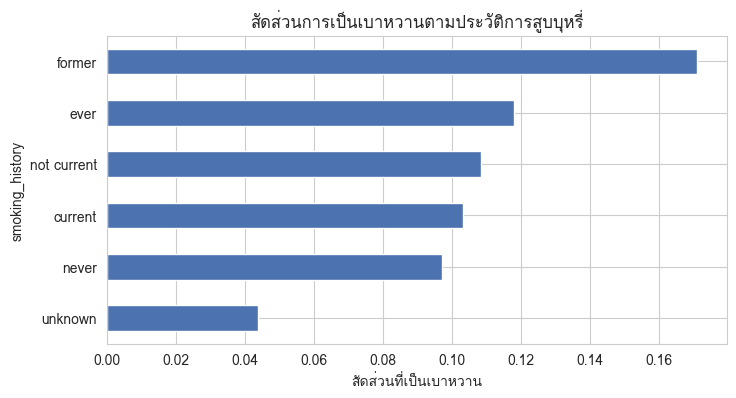

In [ ]:
# กราฟ 4: สัดส่วนการเป็นเบาหวานตามประวัติการสูบบุหรี่ (Bar chart)
plt.figure(figsize=(8, 4))
smoke_rate = df_clean.groupby("smoking_history")["diabetes"].apply(lambda s: (s.astype(int) == 1).mean())
smoke_rate.sort_values().plot(kind="barh", color="#4C72B0")
plt.title("สัดส่วนการเป็นเบาหวานตามประวัติการสูบบุหรี่")
plt.xlabel("สัดส่วนที่เป็นเบาหวาน")
plt.show()

**คำอธิบาย:** กลุ่มที่เคย/กำลังสูบบุหรี่ (former, current, ever) มีสัดส่วนการเป็นเบาหวานสูงกว่ากลุ่มที่ไม่เคยสูบ (never) ชี้ว่าพฤติกรรมการสูบบุหรี่มีความสัมพันธ์กับความเสี่ยง

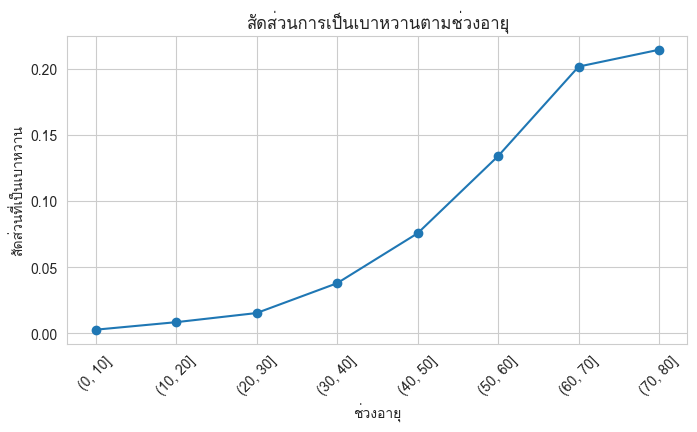

In [ ]:
# กราฟ 5: สัดส่วนการเป็นเบาหวานตามช่วงอายุ (Line chart)
df_clean["age_group"] = pd.cut(df_clean["age"], bins=range(0, 90, 10))

plt.figure(figsize=(8, 4))
age_rate = df_clean.groupby("age_group", observed=True)["diabetes"].apply(lambda s: (s.astype(int) == 1).mean())
age_rate.plot(kind="line", marker="o")
plt.title("สัดส่วนการเป็นเบาหวานตามช่วงอายุ")
plt.xlabel("ช่วงอายุ")
plt.ylabel("สัดส่วนที่เป็นเบาหวาน")
plt.xticks(rotation=45)
plt.show()

**คำอธิบาย:** ความเสี่ยงเพิ่มขึ้นตามช่วงอายุที่มากขึ้นอย่างชัดเจน สอดคล้องกับที่อายุเป็นปัจจัยเสี่ยงสำคัญของโรคเรื้อรัง

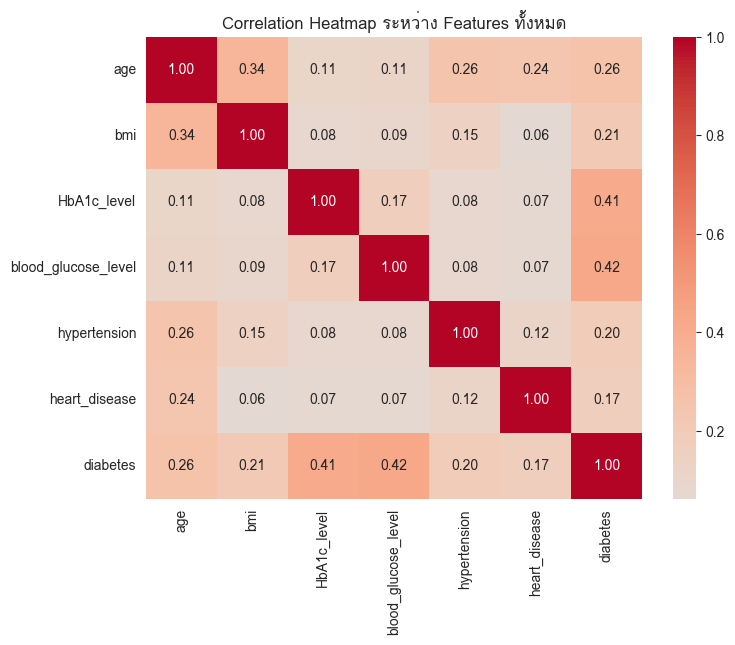

In [ ]:
# กราฟ 6: Correlation Heatmap ของ features ทั้งหมด
numeric_df = df_clean[["age", "bmi", "HbA1c_level", "blood_glucose_level"]].copy()
numeric_df["hypertension"] = df_clean["hypertension"].astype(int)
numeric_df["heart_disease"] = df_clean["heart_disease"].astype(int)
numeric_df["diabetes"] = df_clean["diabetes"].astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap ระหว่าง Features ทั้งหมด")
plt.show()

**คำอธิบาย:** `blood_glucose_level`, `HbA1c_level`, `age`, และ `bmi` มีความสัมพันธ์กับ `diabetes` สูงสุดตามลำดับ ซึ่งจะเป็น feature หลักที่ใช้สร้างโมเดลใน Part 2

## **Summary project progress**

สรุปสิ่งที่ทำไปแล้วใน Part 1

**ขั้นที่ 1: นำเข้าข้อมูล (Import Dataset)**
ดาวน์โหลดชุดข้อมูล Diabetes Prediction Dataset จาก Kaggle ผ่านไลบรารี kagglehub (100,000 แถว, 9 คอลัมน์) แล้วโหลดเข้า pandas DataFrame เพื่อเตรียมวิเคราะห์ต่อ

**ขั้นที่ 2: ทำความสะอาดข้อมูล (Data Cleansing)**
ตรวจสอบ missing value (ไม่พบค่า NaN แต่พบค่า 'No Info' ใน smoking_history จึงจัดเป็นหมวด 'unknown' แทนการลบทิ้ง) ตรวจและลบแถวที่ซ้ำกัน (duplicate) ตรวจ outlier ของ bmi ด้วย boxplot และแปลงคอลัมน์กลุ่ม binary/categorical (hypertension, heart_disease, diabetes, gender, smoking_history) ให้เป็น dtype ที่เหมาะสม

**ขั้นที่ 3: สำรวจข้อมูลเชิงลึก (Exploratory Data Analysis)**
สร้างกราฟทั้งหมด 6 รูปเพื่อดูความสัมพันธ์ระหว่าง feature ต่าง ๆ กับการเป็นเบาหวาน ได้แก่ สัดส่วนคนเป็น/ไม่เป็นเบาหวาน, HbA1c_level และ blood_glucose_level เทียบระหว่างกลุ่ม, BMI เทียบระหว่างกลุ่ม, สัดส่วนการเป็นเบาหวานตามประวัติการสูบบุหรี่, สัดส่วนการเป็นเบาหวานตามช่วงอายุ และ correlation heatmap ของทุก feature

**ขั้นที่ 4: สรุปผลที่ได้**
พบว่า blood_glucose_level, HbA1c_level, age และ bmi มีความสัมพันธ์กับการเป็นเบาหวานสูงสุดตามลำดับ สอดคล้องกับความรู้ทางการแพทย์ และพบว่าข้อมูลมีลักษณะ imbalanced ระหว่างกลุ่มเป็น/ไม่เป็นโรค ซึ่งต้องนำไปพิจารณาต่อใน Part 2

**สิ่งที่จะทำต่อไป (Part 2):** data preprocessing (encode categorical, scale ตัวเลข, จัดการ imbalanced) แล้วสร้างและประเมินแบบจำลอง Machine Learning ต่อไป

---


จากการสำรวจข้อมูลเบื้องต้น (EDA) ของชุดข้อมูล Diabetes Prediction Dataset (100,000 แถว) พบว่าข้อมูลชุดนี้มีความพร้อมและมีความเหมาะสมสำหรับนำไปใช้ทำนายความเสี่ยงโรคเบาหวานในโปรเจกต์นี้ โดยสรุปประเด็นสำคัญได้ดังนี้

**การทำความสะอาดข้อมูล:** ไม่พบ missing value แบบ NaN แต่พบค่า 'No Info' ในคอลัมน์ smoking_history จำนวนหนึ่ง จึงเลือกจัดเป็นหมวดหมู่ 'unknown' แทนการลบทิ้ง เพื่อไม่ให้เสียข้อมูลของแถวอื่น ๆ ไปด้วย และได้ตรวจสอบพร้อมลบแถวที่ซ้ำกัน (duplicate) ออกเรียบร้อยแล้ว

**ความสัมพันธ์ของตัวแปรกับ diabetes:** จาก correlation heatmap พบว่า blood_glucose_level, HbA1c_level, age และ bmi มีความสัมพันธ์กับการเป็นเบาหวานสูงที่สุดตามลำดับ ซึ่งสอดคล้องกับหลักการทางการแพทย์ที่ใช้ค่าน้ำตาลในเลือดและ HbA1c ในการวินิจฉัยโรคโดยตรง

**ปัจจัยด้านพฤติกรรมและประชากรศาสตร์:** ผู้ที่เคยหรือกำลังสูบบุหรี่ (former, current, ever) มีสัดส่วนการเป็นเบาหวานสูงกว่ากลุ่มที่ไม่เคยสูบ (never) อย่างชัดเจน ความเสี่ยงยังเพิ่มขึ้นตามช่วงอายุที่มากขึ้น และกลุ่มที่เป็นเบาหวานมีค่า BMI เฉลี่ยสูงกว่ากลุ่มที่ไม่เป็นเช่นกัน ซึ่งสอดคล้องกับความรู้ทางการแพทย์ว่าน้ำหนักเกิน/อ้วนเป็นปัจจัยเสี่ยงสำคัญ

**ข้อควรระวัง:** ข้อมูลมีลักษณะ imbalanced ระหว่างกลุ่มเป็น/ไม่เป็นโรคอย่างชัดเจน (กลุ่มไม่เป็นเบาหวานมีจำนวนมากกว่ามาก) ซึ่งเป็นประเด็นสำคัญที่ต้องนำไปพิจารณาต่อในขั้นตอนการสร้างแบบจำลอง เช่น การทำ resampling หรือการปรับ class weight เพื่อไม่ให้โมเดลเอนเอียงไปทางกลุ่มที่มีจำนวนมากกว่า

**ขั้นตอนต่อไป (Part 2):** จะดำเนินการ data preprocessing เพิ่มเติม ได้แก่ การ encode ตัวแปร categorical (gender, smoking_history) การ scale ตัวแปรตัวเลข และการจัดการปัญหาข้อมูล imbalanced จากนั้นจึงสร้างและประเมินแบบจำลอง Machine Learning สำหรับทำนายความเสี่ยงโรคเรื้อรังต่อไป

## **Data pre-processing**

## **Build Machine Learning Model**

Model name

Evaluate Model

## **Summary**